# QPDK gatemon test chip — two carbon-nanotube gatemons on λ/2 transmission resonators (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/gatemon_test_chip.pic.yml`, with the
cells `qpdk/cells/gatemon.py` (`gatemon`, `gatemon_coupler`), <https://github.com/gdsfactory/quantum-rf-pdk> —
**MIT licence** (gdsfactory 2024; depth-1 clone read 2026-11-03, never executed). Spec:
`docs/designs/qpdk/gatemon_test_chip.md`. Reference in the YAML: Riechert et al., carbon-nanotube gatemon, Nat.
Commun. 2025 (doi 10.1038/s41467-025-62283-y). Two independent, mirror-image channels (a = south, b = north).
Each runs launcher → series IDC → a 600 µm `gatemon_coupler` straight where the gatemon island couples (200 µm
from its start) → meander → tail → series IDC → launcher: a **λ/2 resonator in transmission**, 11946 µm long.
Each gatemon has a gate electrode routed to its own launcher.

This notebook **rebuilds** the chip on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm chip | the same 10 × 10 mm (it does not fit the 7.5 mm die), Quantcore die frame, device ID "QPDK-GTC"; Designer = source + (5000, 5000) µm before centring |
| pads | QPDK `launcher`, 150 µm from the chip edge | `BondPad`s **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| placement | the circuit 500 µm east of the chip centre | the circuit centred in the die: shifted **−500 µm** in x (the gate pads follow along their edges) |
| substrate | Si (εr 11.45) | sapphire 650 µm, εr 10.25 |
| weak link | gate-tunable carbon nanotube (CNT contacts, nanotube, hBN, Al patch, top gate) | **no tunnel junction to replace**: no Quantcore trilayer junction applies; the CNT layers have no PDK v3 fab layer (not drawn); the LOM keeps a fixed L_J = 20 nH (assumed), C_J = 2 fF |
| cheese | none (unfilled sample; QPDK's `filled_gatemon_test_chip` is a separate variant) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) |
| components, lengths | — | kept: the six launchers, both IDC pairs, the 11946 µm λ/2 between the IDCs (600 µm coupler + 11346 µm route), the gate lines with QPDK's waypoints, the YAML targets (bare cavity 5.056 GHz, E_C/h 260 MHz, 5.4 fF coupling) |

**`Gatemon` and `GatemonCoupler`** are Quantcore re-implementations of QPDK `gatemon` / `gatemon_coupler` (MIT)
at the QPDK defaults: a 150 µm island in its pocket (60 µm side gaps, 40 µm to the line), the M1 gate feed and a
gate CPW out of the pocket; a 600 µm through-CPW whose gap opens into the pocket. Channel b is mirrored as in
QPDK (gate on the same side as a).

**Substituted / estimated:** the coupling is the cell's nominal 5.4 fF (QPDK's `coupling_capacitance`, not an
extraction); the island's C to ground is lom's analytic 51 fF (QPDK's calibrated C_Σ is 75 fF). The KQC IDC is
longer than QPDK's (port `b` 18.5 µm further east), so the coupler, the gatemon and the gate line's last waypoint
move 18.5 µm east with it. The meander is the router's KQC `Meander` on a vertical leg (5 turns, r = 50 µm);
total length exact. Launcher ports sit 110 µm further in than QPDK's (BondPad's gap also runs behind the pad).

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in step 13 (`qcc mask` does the
full file). `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks (launcher, double-pad transmon,
IDC, the trilayer SQUID, the die box and the centring check).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/gatemon_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 5000, 5000                              # Designer = QPDK source + (X0, Y0), before centring

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The weak link.** A gatemon's junction is a gate-tunable semiconductor weak link (here a carbon nanotube), not
a Josephson tunnel junction, so the PDK trilayer junction does not apply and nothing is sized on the PDK rule.
The LOM needs an inductance: `JJ` is a fixed L_J of 20 nH (assumed, from the spec) with C_J 2 fF; in the source
the gate voltage tunes it (step 12 changes it).

In [4]:
JJ = {"Lj_nH": 20.0, "Cj_fF": 2.0}               # assumed (CNT weak link, gate-tunable in the source)
L_RES = 11946.135                                # 600 coupler + 9946.135 meander + 1400 tail (QPDK)
L_CPL = 600.0                                    # gatemon_coupler length (part of the λ/2)
IDC_SHIFT = 18.5                                 # KQC IDC port b sits 18.5 µm east of QPDK cap_in o2 (−1963.5 vs −1982)
print(JJ)

{'Lj_nH': 20.0, 'Cj_fF': 2.0}


## 3 · The die and its frame

The source's 10 × 10 mm chip (Designer coordinates = QPDK's + (5000, 5000) µm until the centring step), the
Quantcore die frame and the device ID "QPDK-GTC". No `with_grid`: the source has no cheese, so the build draws
the PDK band.

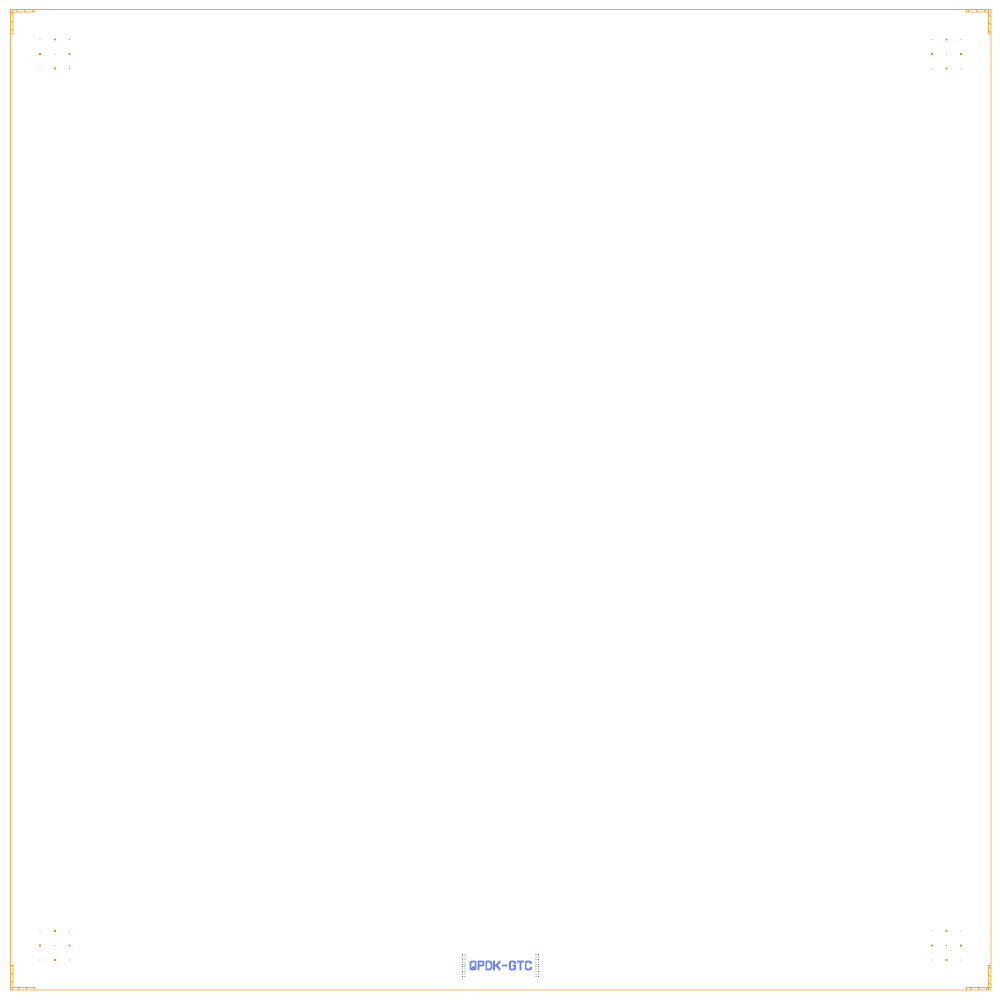

In [5]:
d = Designer("gatemon_test_chip", box=(0, 0, 10000, 10000), chip={"name_chip": "QPDK-GTC"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400);

## 4 · Pads and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Six launchers per chip: for each channel an input (west), an output (east) and a gate launcher (south edge for
channel a, north for b). In the source they sit 150 µm from the chip edge; the rule moves them 50 µm out.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PIN_A | `BondPad` | w | 100.0 | ✓ |
| POUT_A | `BondPad` | e | 100.0 | ✓ |
| PG_A | `BondPad` | s | 100.0 | ✓ |
| PIN_B | `BondPad` | w | 100.0 | ✓ |
| POUT_B | `BondPad` | e | 100.0 | ✓ |
| PG_B | `BondPad` | n | 100.0 | ✓ |

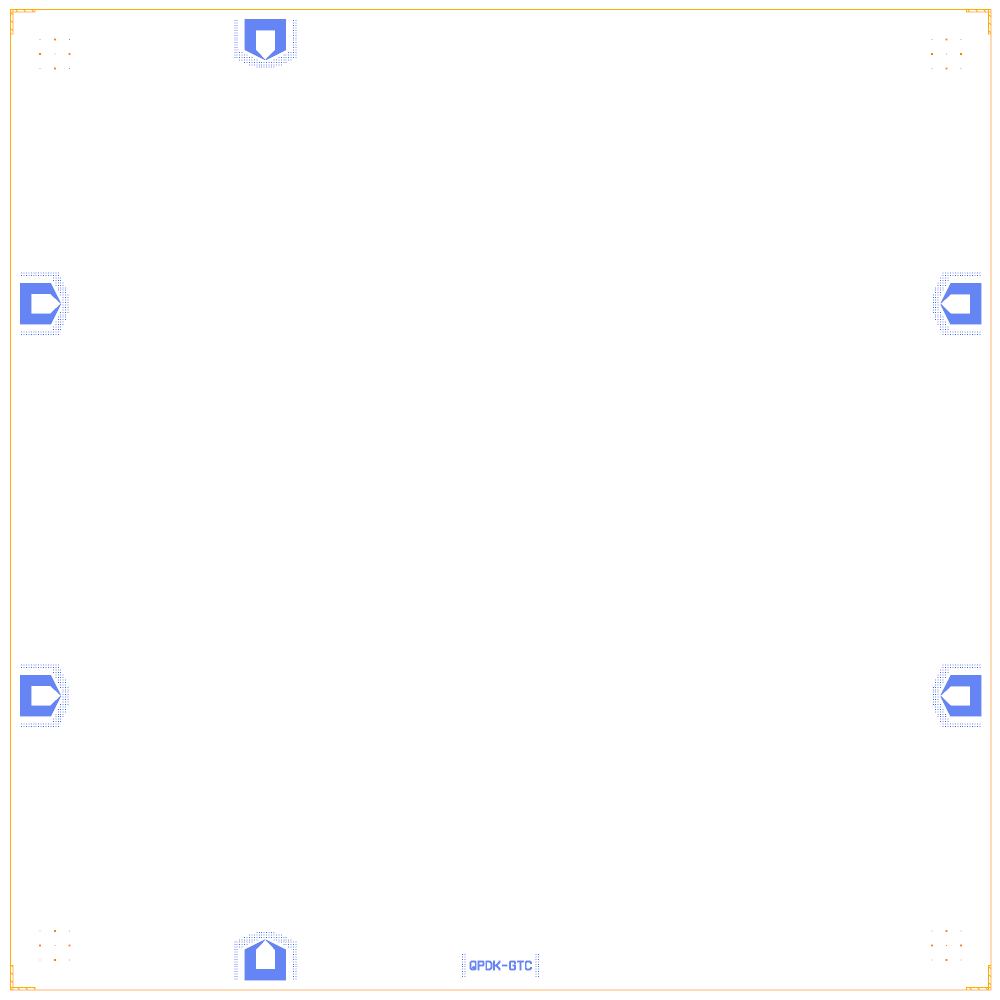

In [6]:
pads = {}
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):         # channel a south (resonator below its line), b north (mirrored)
        y = Y0 + s * 2000
        pads[f"PIN_{ch}"] = d.add(f"PIN_{ch}", "BondPad", at=(150 + QP.LAUNCHER_DEPTH, y), rot=270, edge="auto",
                                  **QP.LAUNCHER)
        pads[f"POUT_{ch}"] = d.add(f"POUT_{ch}", "BondPad", at=(9850 - QP.LAUNCHER_DEPTH, y), rot=90, edge="auto",
                                   **QP.LAUNCHER)
        pads[f"PG_{ch}"] = d.add(f"PG_{ch}", "BondPad", at=(X0 - 2400, Y0 + s * (4850 - QP.LAUNCHER_DEPTH)),
                                 rot=90 + 90 * s, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, STEPS / "2_pads.png", size=(1000, 1000), width=400);

## 5 · Components

Per channel: the input and output IDCs (`QP.IDC`, KQC `FingerCapacitorSquare`); the `GatemonCoupler` snapped
with its `o1` to the input IDC (QPDK connection `coupler o1 → cap_in o2`); the `Gatemon` snapped with its
`readout` to the coupler's `qubit` port (channel a). Channel b's gatemon is mirrored in QPDK; `Designer.add` drops
`mirror` with a snap, so it is placed explicitly on `K_B.qubit` and the connection declared as a wire
(`d.couple(..., wire=True)`). Gatemon ports: `readout`, `gate`, `squid_a` / `squid_b` (weak-link reference
points).

<Gatemon G_A ports=['gate', 'readout', 'squid_a', 'squid_b']>


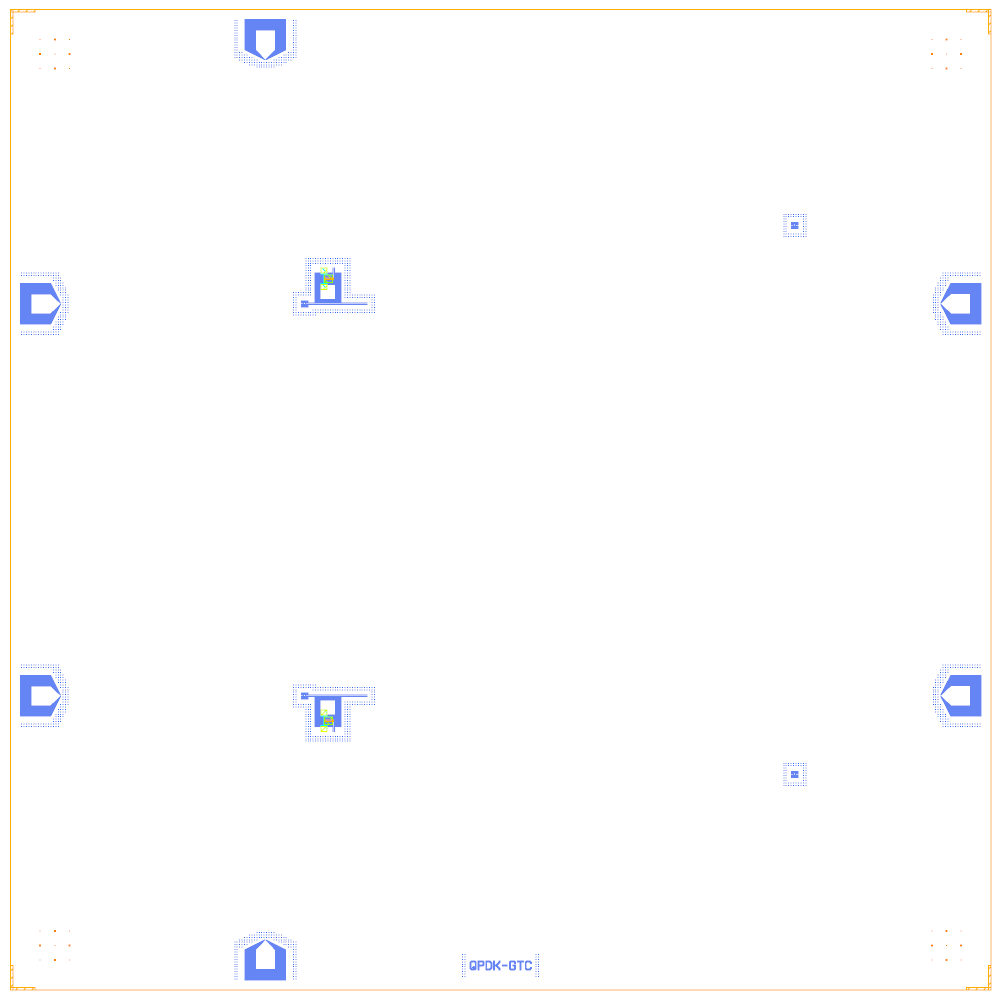

In [7]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        y = Y0 + s * 2000
        ci = d.add(f"CI_{ch}", "FingerCapacitorSquare", at=(X0 - 2000, y), **QP.IDC)
        d.add(f"CO_{ch}", "FingerCapacitorSquare", at=(X0 + 3000, y + s * 800), **QP.IDC)   # QPDK places it by connection
        k = d.add(f"K_{ch}", "GatemonCoupler", snap="o1", to=ci.b, length=L_CPL,
                  qubit_side="bottom" if s < 0 else "top")
        if s < 0:
            d.add(f"G_{ch}", "Gatemon", snap="readout", to=k.qubit, junction=JJ)
        else:  # gatemon_b is mirrored: placed on K_B.qubit (a/2 + pocket_gap_top + island/2 above the line)
            d.add(f"G_{ch}", "Gatemon", at=(X0 - 1782 + IDC_SHIFT, y + 5 + 40 + 75), mirror=True, junction=JJ)
            d.couple(f"W_{ch}", f"G_{ch}.readout", f"K_{ch}.qubit", wire=True, note="QPDK gatemon_b,readout: coupler_b,qubit")
print(d["G_A"])
snap(d, STEPS / "3_components.png", size=(1000, 1000), width=400);

## 6 · Routes

Per channel: the input lead (launcher → IDC); the rest of the λ/2 from the coupler's far end `o2` to the output
IDC — a meander on a vertical leg at x = source + 475 µm (the middle of QPDK's meander field), 5 turns, r = 50 µm,
so that coupler + route = 11946 µm; the output lead with QPDK's turn at x = source + 3300 µm; the gate line with
QPDK's waypoints (+ the IDC shift). One sim group per channel (gatemon, coupler, λ/2, both IDCs; 200 µm margin).

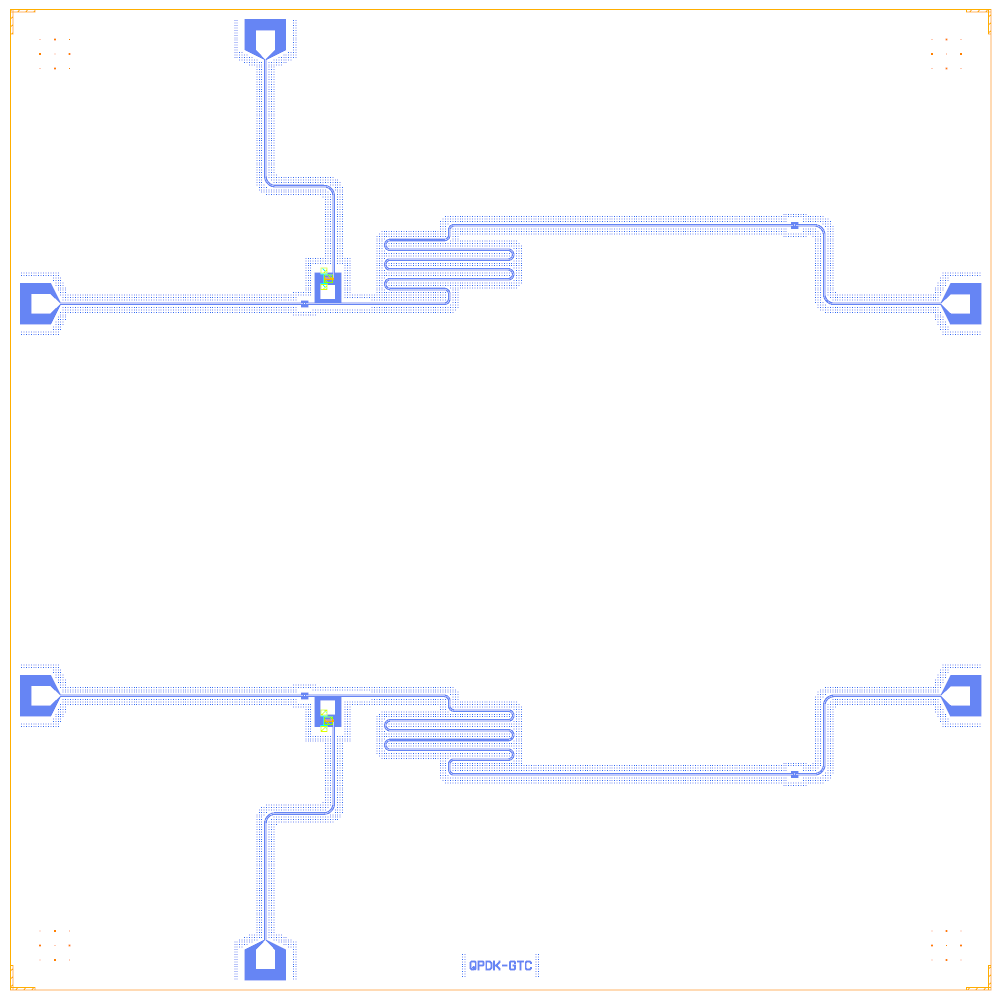

{'IN_A': 2453.5, 'RES_A': 11346.1, 'OUT_A': 2167.7, 'GATE_A': 2734.7, 'IN_B': 2453.5, 'RES_B': 11346.1, 'OUT_B': 2167.7, 'GATE_B': 2734.7}
{'K_A.o1': (3036.5, 3000.0, 180.0), 'G_A.readout': (3236.5, 2955.0, 90.0), 'G_A.gate': (3296.5, 2634.0, -90.0), 'G_B.readout': (3236.5, 7045.0, -90.0), 'G_B.gate': (3296.5, 7366.0, 90.0)}


In [8]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        y = Y0 + s * 2000
        d.route(f"IN_{ch}", f"PIN_{ch}.a", f"CI_{ch}.a", r=QP.CPW_R)
        d.route(f"RES_{ch}", f"K_{ch}.o2", f"CO_{ch}.a", meander=L_RES - L_CPL, r=50,
                nodes=[(X0 - 525, y), (X0 - 525, y + s * 800)]).set(meanders=5, meander_segment=3)
        d.route(f"OUT_{ch}", f"CO_{ch}.b", f"POUT_{ch}.a", nodes=[(X0 + 3300, y + s * 800), (X0 + 3300, y)], r=QP.CPW_R)
        d.route(f"GATE_{ch}", f"PG_{ch}.a", f"G_{ch}.gate",
                nodes=[(X0 - 2400, Y0 + s * 3200), (X0 - 1722 + IDC_SHIFT, Y0 + s * 3200)], r=QP.CPW_R)
        d.sim_group(f"CH_{ch}", [f"G_{ch}", f"K_{ch}", f"RES_{ch}", f"CI_{ch}", f"CO_{ch}"], margin_um=200)
d.targets(RES_A={"f_GHz": 5.056}, RES_B={"f_GHz": 5.056}, G_A={"alpha_MHz": -260}, G_B={"alpha_MHz": -260})
snap(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
print({p: tuple(round(v, 1) for v in port_info(d, p)) for p in ("K_A.o1", "G_A.readout", "G_A.gate", "G_B.readout", "G_B.gate")})

**Centring.** With the pads at the die edge, the check measures the *circuit* (`QP.circuit_box`: every
instance and route except the pads and their lead routes) and `QP.center_circuit` shifts it to the die centre
when it is more than 50 µm off. Pads placed with `edge="auto"` follow the shift along their edge and stay
100 µm (`frame.pad_edge`) from it; hangers follow their feedline. Then the design is saved: the JSON is what DRC, LOM, FEM and
`qcc` read.
Here the circuit (IDCs, couplers, gatemons, resonators) sits 500 µm east of the die centre in the source too
(QPDK's input IDC is at −2000 µm, its output IDC at +3000 µm); it is centred.

In [9]:
SHIFT = QP.center_circuit(d)
print("circuit centring shift (µm):", SHIFT)
rebuild(d)
DESIGN = d.save(OUT / "gatemon_test_chip.json")
print(d, "→", DESIGN)

circuit centring shift (µm): (-500.0, 0.0)


<Designer gatemon_test_chip: 14 instances, 8 routes, live=False> → examples\designs\qpdk\gatemon_test_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included, so a chip with launchers on one side reads
off-centre there) and the junction types.
Here: `dangling_port` × 4 — the `Gatemon` `squid_a` / `squid_b` ports, reference points of the (undrawn) CNT
weak link; `overlap G_B and K_B` — channel b's gatemon is placed explicitly (mirrored) and joined by a declared
wire, so the DRC does not see the snap that exempts channel a: the pocket's etch is meant to open into the line's
gap there. **PDK design warnings:** `pdk_rn` × 2 — the R_n check reads the assumed 20 nH as a tunnel junction
(≈ 134 kΩ); a CNT weak link is not one, so the flag does not apply to this device (kept, reported).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 5 warnings · 2 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | G_A.squid_a is not connected (no route or snap) |
| warning | `overlap` | 1 | G_B and K_B overlap |
| PDK design warning | `pdk_rn` | 2 | G_A: junction R_n 133.6 kΩ is outside the PDK window 40–50 kΩ (L_J 20.0 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 2 (pdk_rn × 2) |
| pdk_rn | G_A: junction R_n 133.6 kΩ is outside the PDK window 40–50 kΩ (L_J 20.0 nH) |
| pdk_rn | G_B: junction R_n 133.6 kΩ is outside the PDK window 40–50 kΩ (L_J 20.0 nH) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
**Known gap (requested from lom):** the λ/2 is not in this LOM. The LOM builder joins the coupler's 600 µm line
and the 11346 µm meander route into one chain between the two IDCs, but because `GatemonCoupler`'s line is not a
resonator line and neither end is open or shorted, it treats the chain as a **wire** (node `CI_x.b` holds
`CI_x.b`, `CO_x.a` and `K_x.line`). So the simulation below has the gatemon but no resonator, g, χ or κ.

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('G_A.', 'K_A.', 'CI_A',)))))

**11 nodes · 28 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `CI_A.a` | `PIN_A.pad`, `CI_A.a` |
| `CO_A.b` | `POUT_A.pad`, `CO_A.b` |
| `G_A.gate` | `PG_A.pad`, `G_A.gate` |
| `CI_B.a` | `PIN_B.pad`, `CI_B.a` |
| `CO_B.b` | `POUT_B.pad`, `CO_B.b` |
| `G_B.gate` | `PG_B.pad`, `G_B.gate` |
| `CI_A.b` | `CI_A.b`, `CO_A.a`, `K_A.line` |
| `G_A` | `K_A.qubit`, `G_A.island` |
| `CI_B.b` | `CI_B.b`, `CO_B.a`, `K_B.line` |
| `G_B` | `K_B.qubit`, `G_B.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PIN_A` | R | `CI_A.a` – `gnd` | 50 Ω |
| `Port_POUT_A` | R | `CO_A.b` – `gnd` | 50 Ω |
| `Port_PG_A` | R | `G_A.gate` – `gnd` | 50 Ω |
| `Port_PIN_B` | R | `CI_B.a` – `gnd` | 50 Ω |
| `Port_POUT_B` | R | `CO_B.b` – `gnd` | 50 Ω |
| `Port_PG_B` | R | `G_B.gate` – `gnd` | 50 Ω |
| `C_CI_A` | C | `CI_A.a` – `CI_A.b` | 6.12 fF |
| `C_CI_A_a` | C | `CI_A.a` – `gnd` | 2.7 fF |
| `C_CI_A_b` | C | `CI_A.b` – `gnd` | 2.7 fF |
| `C_CO_A` | C | `CI_A.b` – `CO_A.b` | 6.12 fF |
| `C_CO_A_a` | C | `CI_A.b` – `gnd` | 2.7 fF |
| `C_CO_A_b` | C | `CO_A.b` – `gnd` | 2.7 fF |
| `Cg_K_A` | C | `CI_A.b` – `G_A` | 5.4 fF |
| `C_G_A` | C | `G_A` – `gnd` | 51.1 fF |
| `J_G_A` | JJ | `G_A` – `gnd` | Lj 20 nH, Cj 2 fF |
| `Cgate_G_A` | C | `G_A` – `G_A.gate` | 0.2 fF |
| `C_G_A_gate` | C | `G_A.gate` – `gnd` | 16 fF |
| `C_CI_B` | C | `CI_B.a` – `CI_B.b` | 6.12 fF |
| `C_CI_B_a` | C | `CI_B.a` – `gnd` | 2.7 fF |
| `C_CI_B_b` | C | `CI_B.b` – `gnd` | 2.7 fF |
| `C_CO_B` | C | `CI_B.b` – `CO_B.b` | 6.12 fF |
| `C_CO_B_a` | C | `CI_B.b` – `gnd` | 2.7 fF |
| `C_CO_B_b` | C | `CO_B.b` – `gnd` | 2.7 fF |
| `Cg_K_B` | C | `CI_B.b` – `G_B` | 5.4 fF |
| `C_G_B` | C | `G_B` – `gnd` | 51.1 fF |
| `J_G_B` | JJ | `G_B` – `gnd` | Lj 20 nH, Cj 2 fF |
| `Cgate_G_B` | C | `G_B` – `G_B.gate` | 0.2 fF |
| `C_G_B_gate` | C | `G_B.gate` – `gnd` | 16 fF |

**Unconnected ports:** none

**Builder notes:**

- G_A: the CNT junction is not drawn; modelled as a JJ with the design's junction values
- G_B: the CNT junction is not drawn; modelled as a JJ with the design's junction values

**Ports → circuit nodes:**

| port | node |
|---|---|
| `CI_A.a` | `CI_A.a` |
| `CI_A.b` | `CI_A.b` |
| `G_A.gate` | `G_A.gate` |
| `G_A.readout` | `G_A` |
| `G_A.squid_a` | `G_A` |
| `G_A.squid_b` | `gnd` |
| `K_A.o1` | `CI_A.b` |
| `K_A.o2` | `CI_A.b` |
| `K_A.qubit` | `G_A` |

## 9 · LOM simulation

Each channel: the gatemon, its coupler, the λ/2 route, both IDCs, the leads and the pads. Targets from the YAML
`info` (in brackets): bare cavity 5.056 GHz (on Si), E_C/h 260 MHz (|α| ≈ E_C). f_q follows from the assumed
L_J; α from lom's rough island C (51 fF + 5.4 fF coupler + 2 fF C_J vs QPDK's calibrated 75 fF C_Σ), so |α|
comes out above 260 MHz.

In [12]:
groups = {f"CH_{c}": [f"G_{c}", f"K_{c}", f"RES_{c}", f"CI_{c}", f"CO_{c}", f"IN_{c}", f"OUT_{c}", f"PIN_{c}", f"POUT_{c}"]
          for c in "AB"}
res = simulate_groups(d, groups)
TARGETS = {"RES_A": {"f_GHz": 5.056}, "RES_B": {"f_GHz": 5.056}, "G_A": {"alpha_MHz": -260}, "G_B": {"alpha_MHz": -260}}
display(Markdown(groups_md(res, TARGETS)))
for g, r in res.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| CH_A | G_A | 4.3281 | -420.8 (-260) | – | – | – | – |
| CH_B | G_B | 4.3281 | -420.8 (-260) | – | – | – | – |

**CH_A, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| G_A | qubit | 4.6960 | 0.496 | 337.3 | J_G_A 1.00 |

**CH_B, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| G_B | qubit | 4.6960 | 0.496 | 337.3 | J_G_B 1.00 |

## 10 · FEM: send the jobs
Per channel a Q3D C-matrix job and an eigenmode / EPR job (gatemon, coupler, λ/2 and both IDCs; the in / out lines leave the box in 50 Ω).
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs`
solves each Ansys job in a **new batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open
is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

4 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| CH_A · eigenmode_epr | `build/jobs/gatemon_test_chip_CH_A_eigenmode_epr` | 1 · junction · `G_A.junction`<br>2 · edge_lumped · `GATE_A`<br>3 · edge_lumped · `IN_A`<br>4 · edge_lumped · `OUT_A` | `G_A.island`, `GATE_A`, `IN_A`, `OUT_A`, `K_A.line` |
| CH_A · q3d_cmatrix | `build/jobs/gatemon_test_chip_CH_A_q3d_cmatrix` | 1 · junction · `G_A.junction`<br>2 · waveguide · `K_A.o2`<br>3 · waveguide · `CO_A.a`<br>4 · edge · `GATE_A`<br>5 · edge · `IN_A`<br>6 · edge · `OUT_A` | `G_A.island`, `K_A.o2`, `CO_A.a`, `GATE_A`, `IN_A`, `OUT_A` |
| CH_B · eigenmode_epr | `build/jobs/gatemon_test_chip_CH_B_eigenmode_epr` | 1 · junction · `G_B.junction`<br>2 · edge_lumped · `GATE_B`<br>3 · edge_lumped · `IN_B`<br>4 · edge_lumped · `OUT_B` | `G_B.island`, `GATE_B`, `IN_B`, `OUT_B`, `K_B.line` |
| CH_B · q3d_cmatrix | `build/jobs/gatemon_test_chip_CH_B_q3d_cmatrix` | 1 · junction · `G_B.junction`<br>2 · waveguide · `K_B.o2`<br>3 · waveguide · `CO_B.a`<br>4 · edge · `GATE_B`<br>5 · edge · `IN_B`<br>6 · edge · `OUT_B` | `G_B.island`, `K_B.o2`, `CO_B.a`, `GATE_B`, `IN_B`, `OUT_B` |

## 11 · Bring the results back

A solved job holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`: the C-matrix
(or eigenmode) values replace the component estimates branch by branch, matched by net name, and the table
compares the two; `simulate(filled)` re-runs the LOM on the extracted values. Until then the cell says which
jobs are still waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for CH_A · eigenmode_epr, CH_A · q3d_cmatrix, CH_B · eigenmode_epr, CH_B · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The gate voltage tunes the nanotube's L_J. Lower G_A's L_J from 20 to 15 nH (a gate step): f_q rises roughly as
1/√L_J (≈ +15 %) and α barely moves. Done on a copy (`design_copy`), so the design keeps the assumed 20 nH.

In [15]:
d2 = design_copy(DESIGN)
d2["G_A"].set(junction={"Lj_nH": 15.0, "Cj_fF": 2.0})
after = simulate_groups(d2, {"CH_A": groups["CH_A"]})
display(Markdown("**G_A: L_J 20 → 15 nH**\n\n" + params_delta_md({"CH_A": res["CH_A"]}, after)))

**G_A: L_J 20 → 15 nH**

| parameter | before | after | Δ |
|---|---|---|---|
| `CH_A: G_A.f_q_GHz` | 4.3281 | 5.0597 | +0.7316 |
| `CH_A: G_A.alpha_MHz` | -420.77 | -404.6 | +16.17 |

## 13 · Build and export

**The design file.** `gatemon_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/gatemon_test_chip.json` rebuilds `build/gatemon_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
No junction layers: the CNT weak link is not a trilayer junction, and its contacts / nanotube / hBN / Al patch /
top gate have no PDK v3 fab layer, so on this mask the island has no M1 path to ground. The cheese source is
`build`: the PDK band (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/gatemon_test_chip.json`
writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

examples\designs\_common.py:926: FabLayersDropped: export_fab(gatemon_test_chip): PDK quantcore_nb_sapphire_v1 has no fab layer for qcc gatemon_cnt_contact (600/0): 4 shape(s), qcc gatemon_cnt (601/0): 2 shape(s), qcc gatemon_hbn (602/0): 2 shape(s), qcc gatemon_jj_patch (603/0): 4 shape(s), qcc gatemon_top_gate (604/0): 2 shape(s); not written
  export_fab(d.result, path, report=fab, cheese=cheese, rounding=rounding)


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 8500 |
| 3/0 | M3 | 8495 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 8490 holes on the mask.

**Not in the mask (no PDK fab layer):** qcc gatemon_cnt_contact (600/0) (4), qcc gatemon_cnt (601/0) (2), qcc gatemon_hbn (602/0) (2), qcc gatemon_jj_patch (603/0) (4), qcc gatemon_top_gate (604/0) (2)

→ `build/gatemon_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "CH_A", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}
airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip (compare QPDK's render of the filled variant, shown last); channel a's gatemon on its coupler with
the gate feed; the weak-link region below the island (only the pocket etch and the gate landing are in M1); the
input IDC and the start of the coupler; the die frame's south-west corner; and the gatemon in the **fab view**
(the mask from step 13: 1/0 with the PDK cheese band, 3/0). Boxes are the source positions + the centring shift.

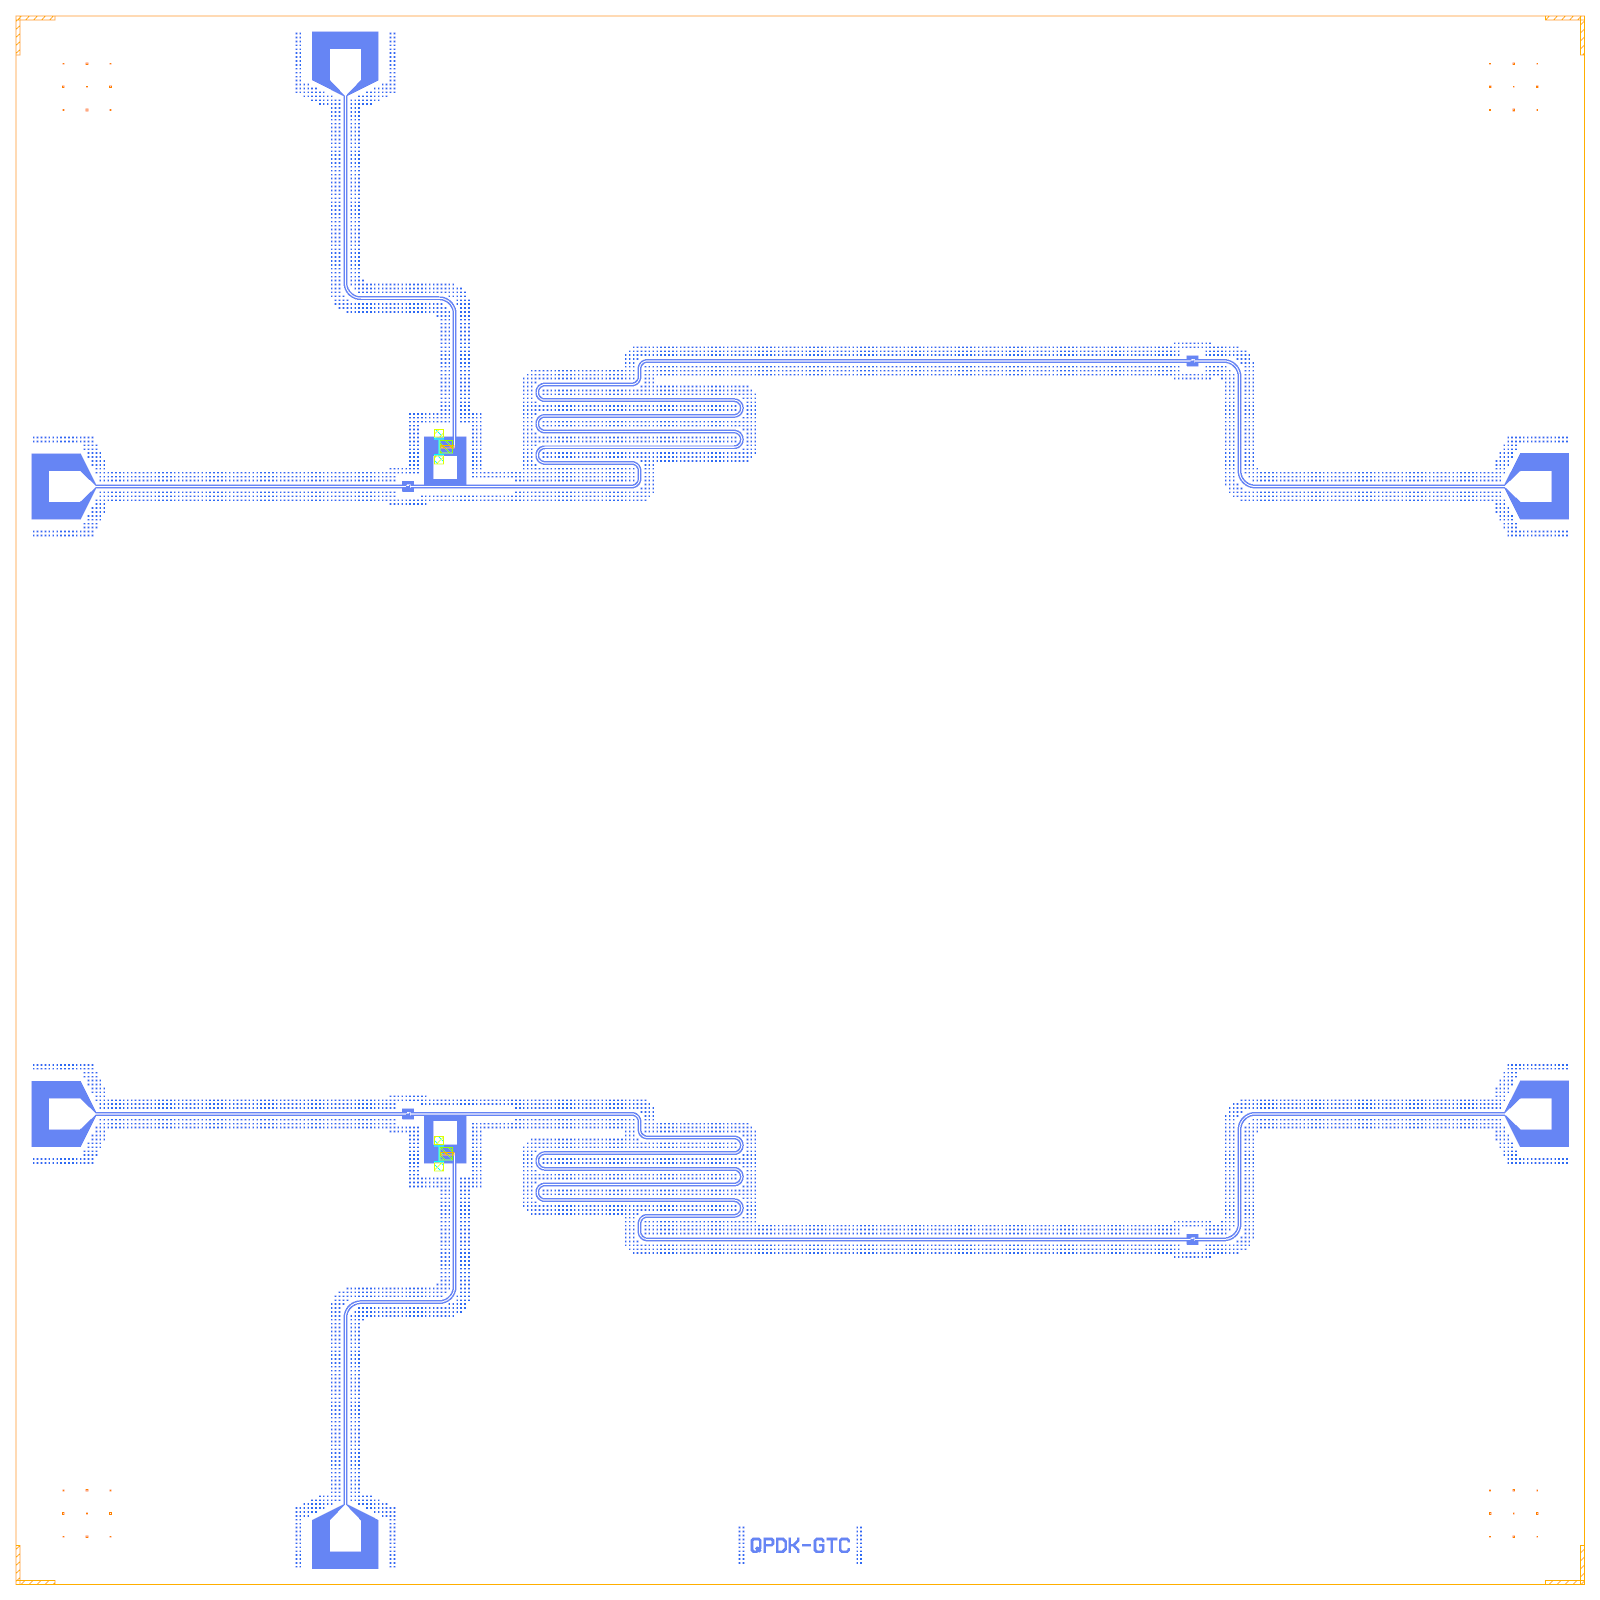

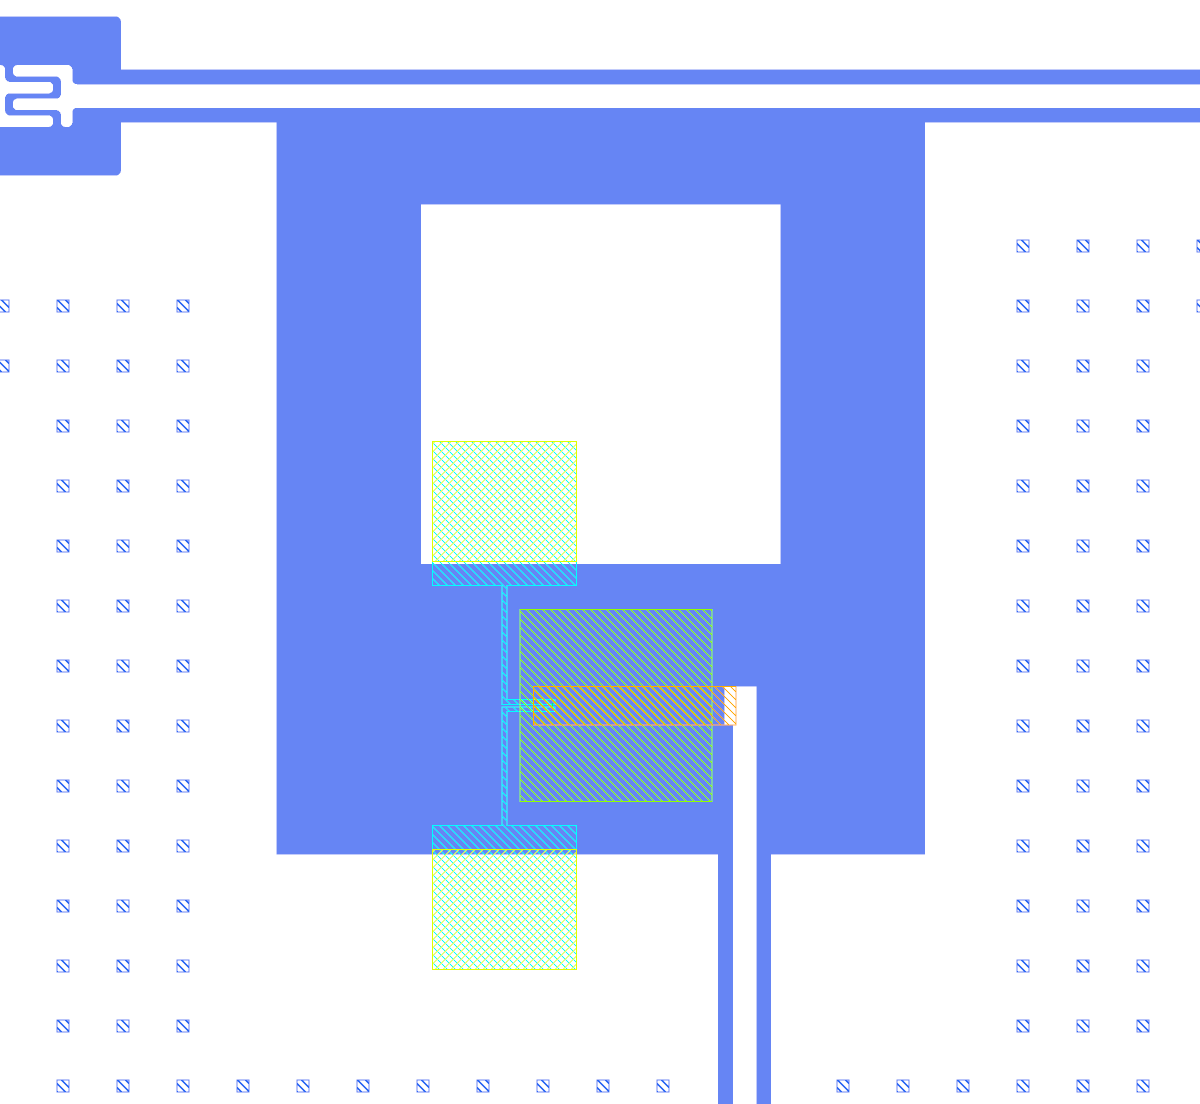

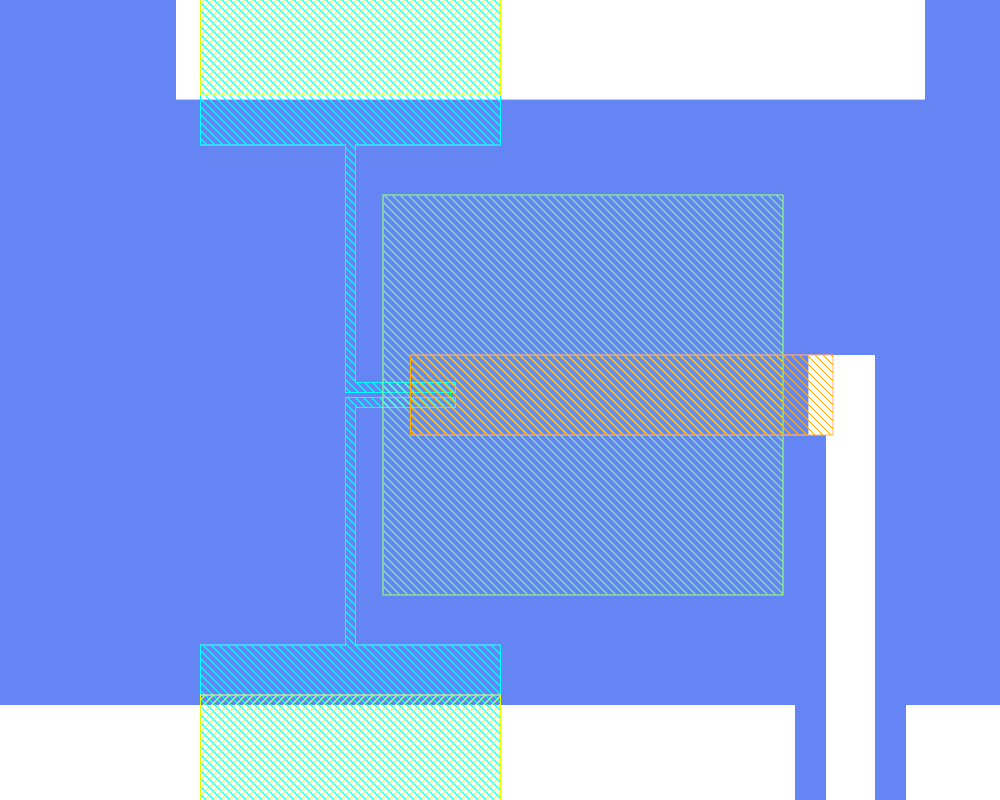

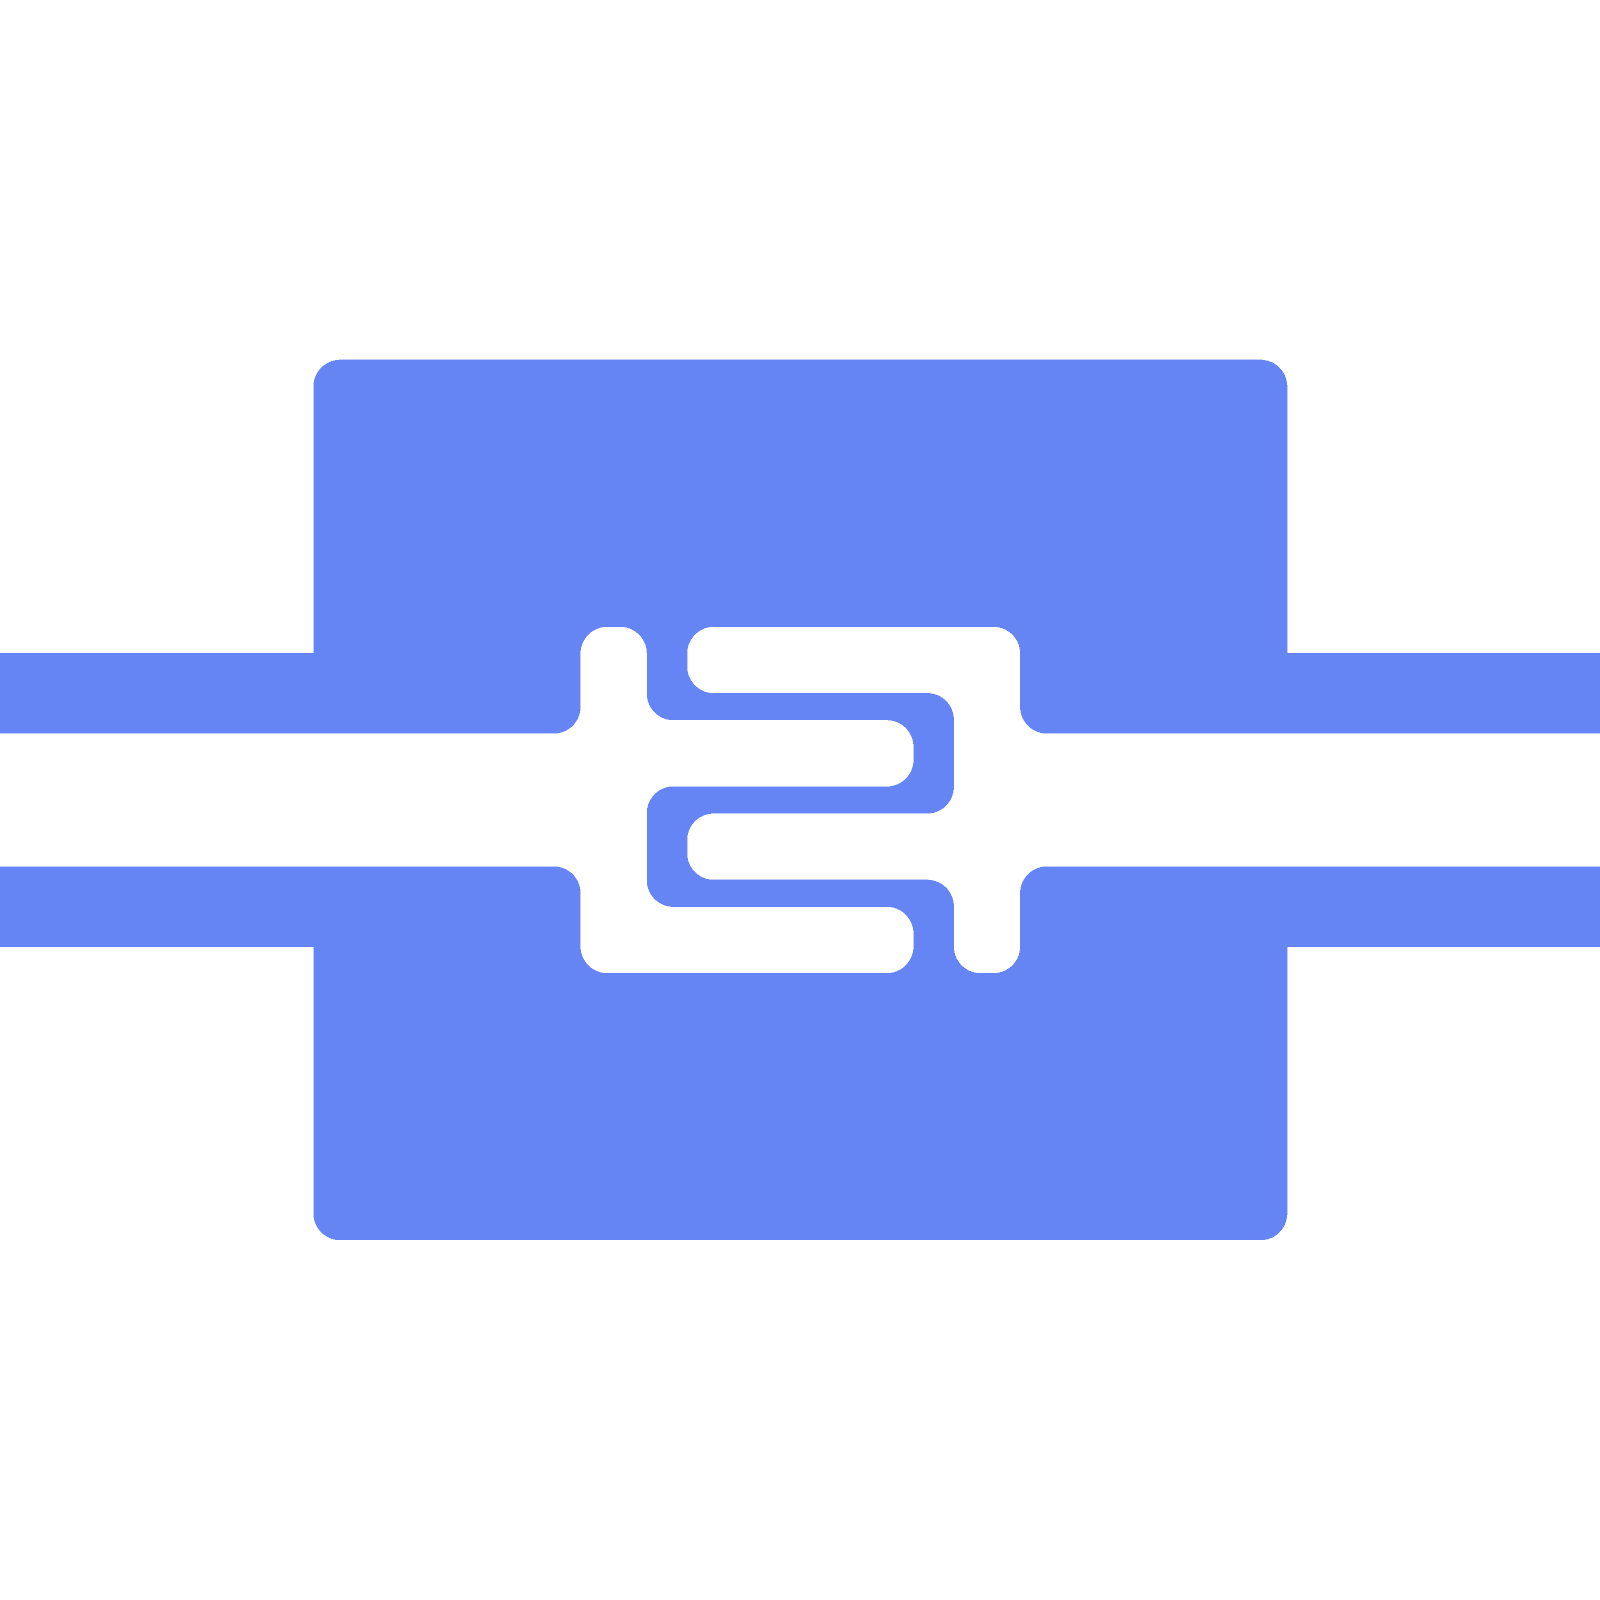

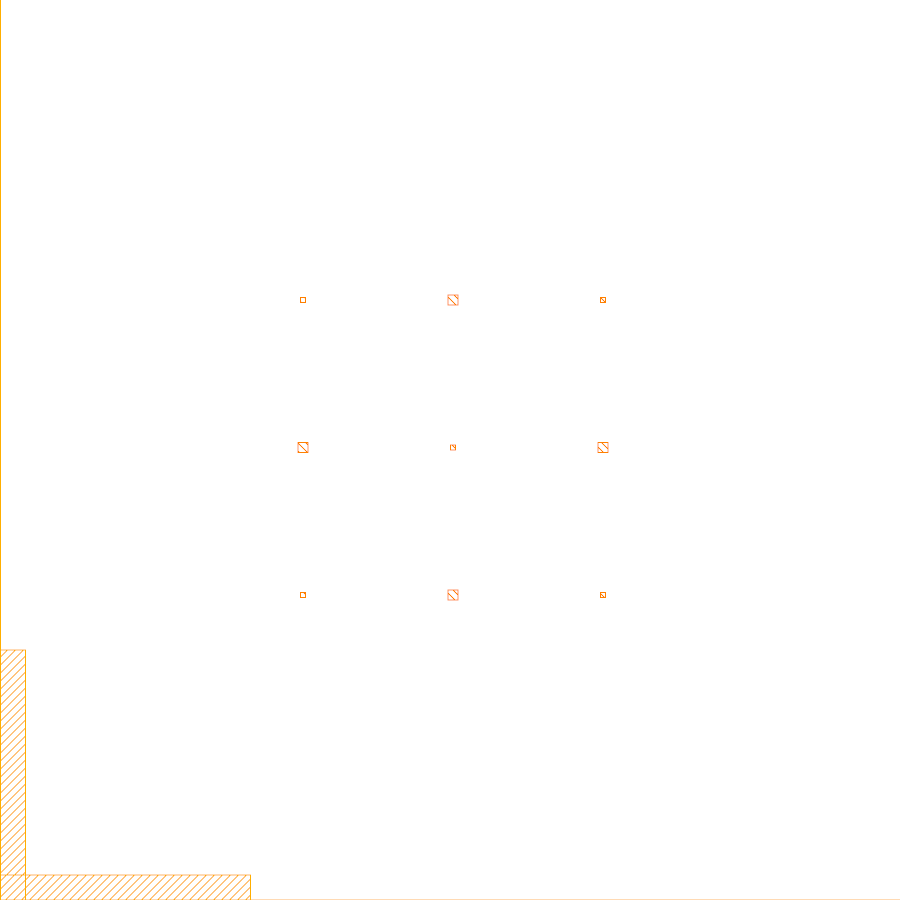

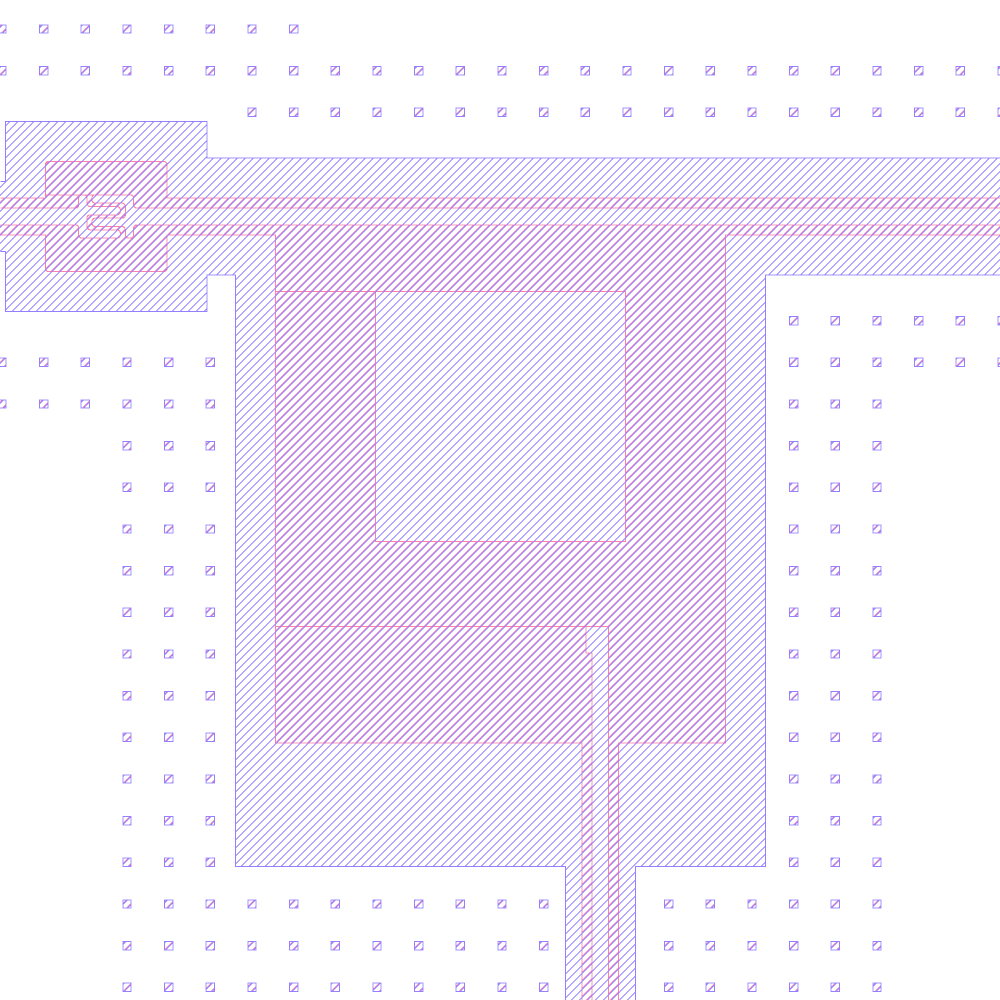

In [18]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "gatemon_test_chip.png", size=(1600, 1600), width=640)
gx, gy = X0 - 1782 + IDC_SHIFT, Y0 - 2000 - 120   # G_A island centre (source frame)
show_snapshot(d, OUT / "gatemon_test_chip_qubit.png", box=box(gx - 250, gy - 300, gx + 250, gy + 160), size=(1200, 1104), width=480)
show_snapshot(d, OUT / "gatemon_test_chip_jj.png", box=box(gx - 110, gy - 215, gx + 90, gy - 55), size=(1000, 800), width=360)
show_snapshot(d, OUT / "gatemon_test_chip_idc.png", box=box(X0 - 2060, Y0 - 2040, X0 - 1940, Y0 - 1960), width=360)
show_snapshot(d, OUT / "gatemon_test_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "gatemon_test_chip_fab.oas", OUT / "gatemon_test_chip_fab_qubit.png",
          box=box(gx - 300, gy - 350, gx + 300, gy + 250), size=(1000, 1000), width=400);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render (of the filled gatemon variant, the only image QPDK publishes for this chip) is shown from the local clone
when present.

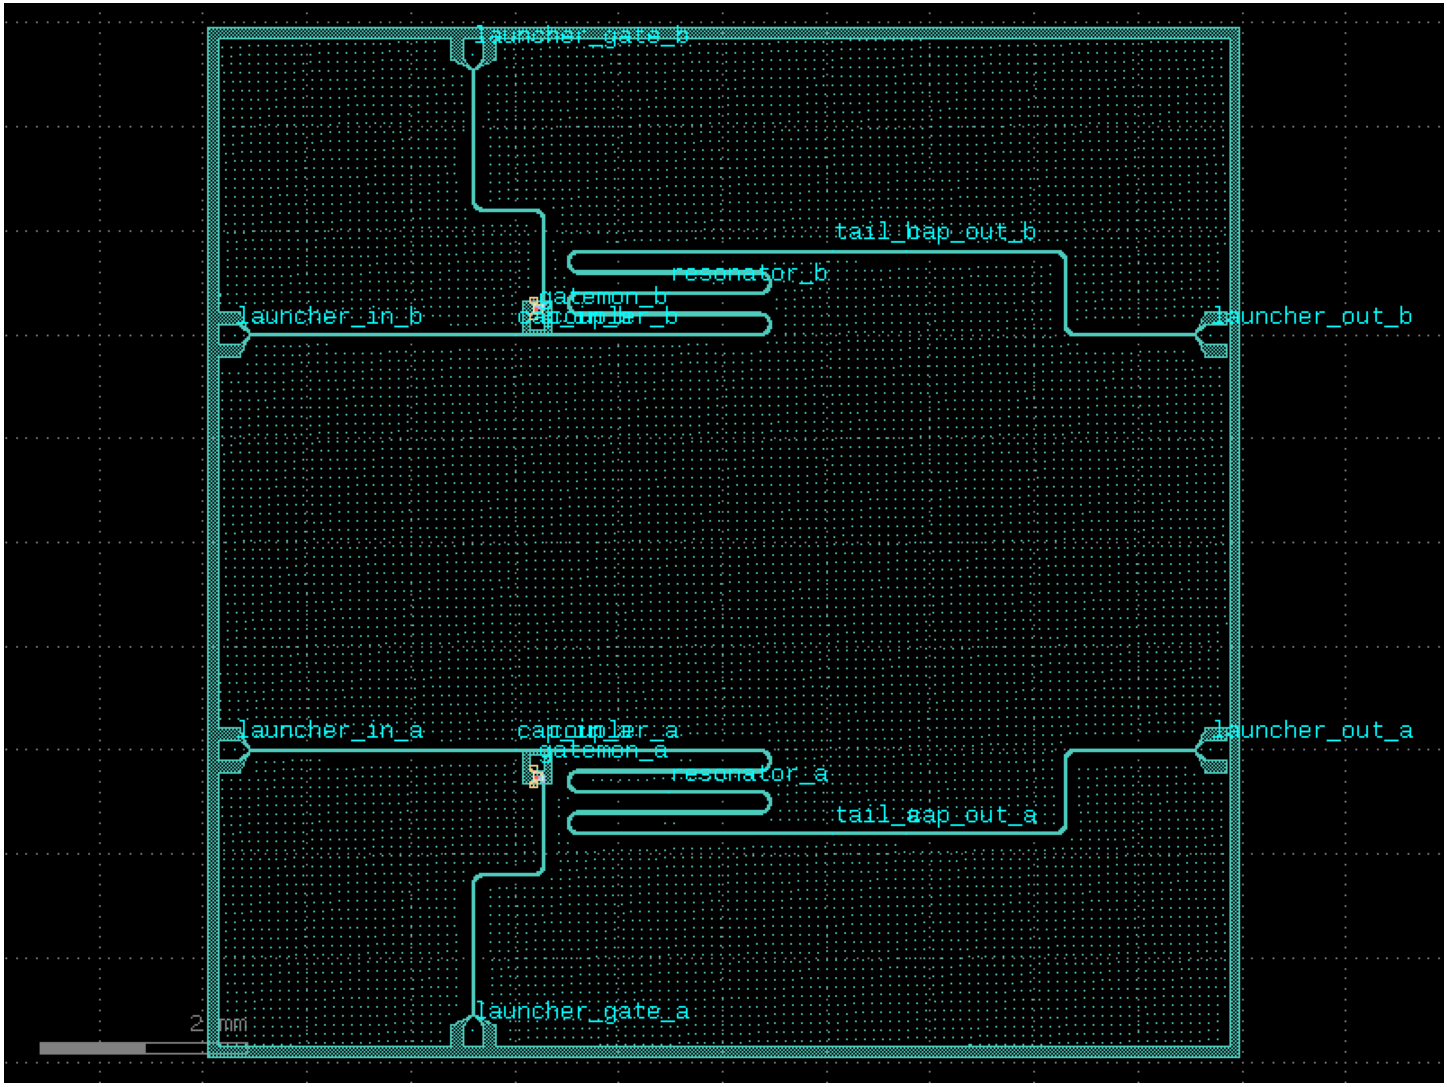

In [19]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "gatemon_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/gatemon_test_chip.png")

## 15 · Summary

| | |
|---|---|
| **matches the source** | both channels: launchers, IDCs, the 600 µm gatemon coupler, the 11946 µm λ/2 between the IDCs, the gatemons (QPDK defaults), the gate lines with QPDK's waypoints, the YAML targets |
| **differs (PDK)** | the Quantcore die frame; pads 100 µm from the edge; the circuit centred (−500 µm in x); sapphire; the PDK cheese band |
| **not drawn / estimated** | the CNT weak link and its process layers (no PDK layer); L_J 20 nH assumed; the λ/2 is a wire in the LOM (lom request) |
| **PDK design warnings** | `pdk_rn` × 2 (the assumed 20 nH read as a tunnel junction; not applicable to a CNT weak link) |
| **FEM** | 4 jobs (2 × Q3D, 2 × eigenmode/EPR) exported to `build/jobs/gatemon_test_chip_*`, not solved here |